In [1]:
import pandas as pd
import numpy as np
from sklearn.impute import SimpleImputer
import matplotlib.pyplot as plt

RANDOM_STATE = 42

#1.Carga de datos
train_data = pd.read_csv("D:/Projectes/Kaggle/titanic/train.csv")
test_data = pd.read_csv("D:/Projectes/Kaggle/titanic/test.csv")

print(train_data.head())
print()
print(test_data.head())
print()
print((train_data["Survived"] == 1).astype(int).sum()/len(train_data))

   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8.0500   NaN        S  

 

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


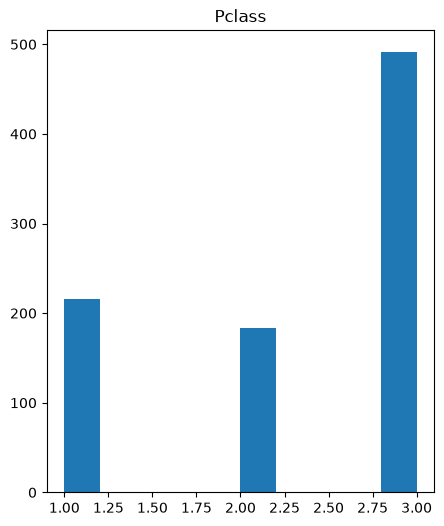

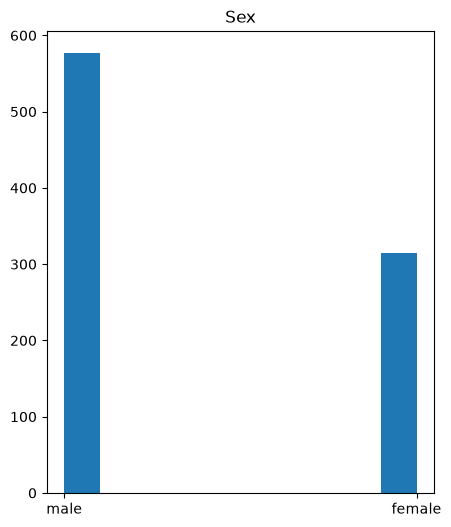

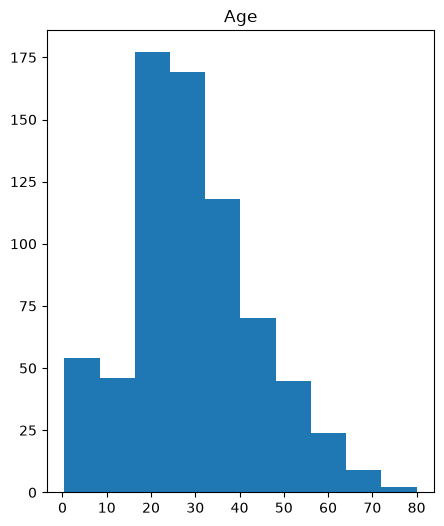

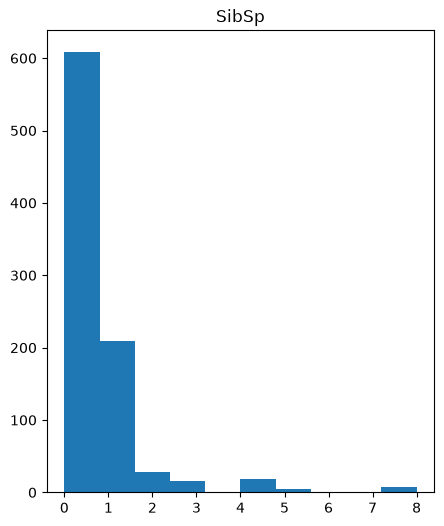

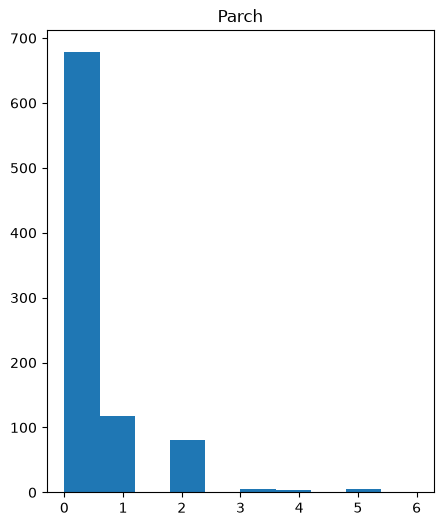

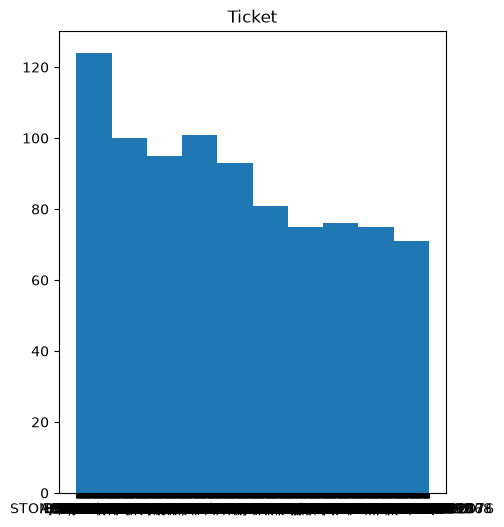

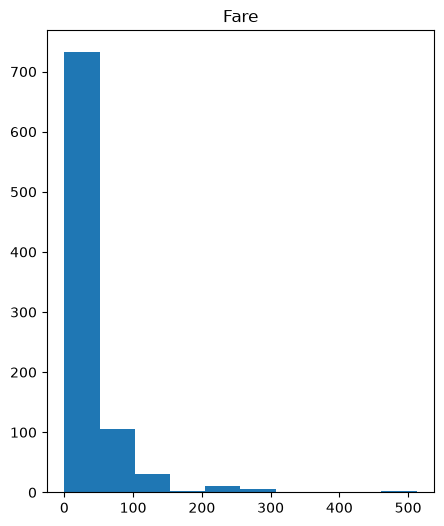

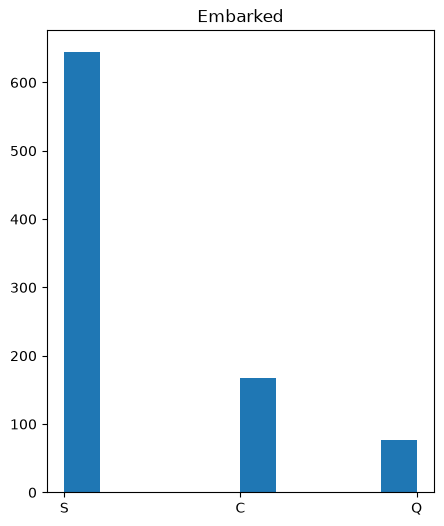

In [2]:
#2.Exploración de los datos
print(train_data.isna().astype(int).sum())
columnas_hist = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Ticket", "Fare", "Embarked"]

for col in columnas_hist:
    plt.figure(figsize=(5,6))
    plt.hist(train_data[col].dropna())
    plt.title(col)
plt.show()

In [3]:
#5.Feature engineering

TITLE_MAP = {"Mr": "Mr", "Mrs": "Mrs", "Mme": "Mrs", "Miss": "Miss", "Mlle": "Miss",
             "Ms": "Miss", "Master": "Master"}  # el resto -> "Rare" (Dr, Rev, Col, Countess...)

def add_features(df: pd.DataFrame ) -> pd.DataFrame:
    out = df.copy()
    title = out["Name"].str.extract(r",\s*([^\.]+)\.", expand=False).str.strip()        #Expand=False para que devuelva un Series
    out["Title"] = title.map(TITLE_MAP).fillna("Rare")
    out["FamilySize"] = out["SibSp"] + out["Parch"] + 1
    out["IsAlone"] = (out["FamilySize"] == 1).astype(int)
    out["HasCabin"] = out["Cabin"].notna().astype(int)
    out["Pclass"] = out["Pclass"].astype(str)
    out["LogFare"] = np.log1p(out["Fare"])                        #Hacemos el log por la asimetría de los datos y esto puede afectar a KNN y LogisticRegression
    return out                                                    #Hacemos log1p (log(1 + Fare)) para que los 0 no den -infinito y den errores más adelante

train_data = add_features(train_data)
test_data = add_features(test_data)



In [4]:
#6.División train/test split

from sklearn.model_selection import train_test_split

FEATURES = ["Pclass", "Sex", "Age", "LogFare", "Embarked", "Title", "FamilySize", "IsAlone", "HasCabin"]

X = train_data[FEATURES]
y = train_data["Survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=RANDOM_STATE
)


In [5]:
#7.Baseline
from sklearn.dummy import DummyClassifier
from sklearn.metrics import classification_report, confusion_matrix

baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train) 
pred_baseline = baseline.predict(X_test)

print(classification_report(y_test, pred_baseline))
print(confusion_matrix(y_test, pred_baseline))


              precision    recall  f1-score   support

           0       0.61      1.00      0.76       110
           1       0.00      0.00      0.00        69

    accuracy                           0.61       179
   macro avg       0.31      0.50      0.38       179
weighted avg       0.38      0.61      0.47       179

[[110   0]
 [ 69   0]]


d:\Projectes\Kaggle\titanic\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\Projectes\Kaggle\titanic\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\Projectes\Kaggle\titanic\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [6]:
#8.Preprocessing + Pipeline
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

num_cols = X.select_dtypes(include="number").columns.to_list()                #select_dtypes te dona les columnes
cat_cols = X.select_dtypes(exclude="number").columns.to_list()
X_train[cat_cols] = X_train[cat_cols].astype(object)                     
 

print(num_cols)
print(cat_cols)
print(X_train[num_cols].dtypes)
print(X_train[cat_cols].dtypes)


preprocessor = ColumnTransformer([
    ("num",
     Pipeline([
         ("imputer_num", SimpleImputer(strategy="mean")),
         ("scaler", StandardScaler())
     ]),
     num_cols),

    ("cat",
     Pipeline([
         ("imputer_cat", SimpleImputer(strategy="most_frequent")),
         ("encoder", OneHotEncoder(handle_unknown="ignore"))
     ]),
     cat_cols)
])

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

from sklearn.model_selection import cross_val_score, StratifiedKFold

#10.Training

pipelines= {}

modelos = {                                             #agafam els models default de tots els models
    "LogisticRegression": LogisticRegression(),
    "KNeighborsClassifier": KNeighborsClassifier(),
    "DecisionTreeClassifier": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "RandomForestClassifier": RandomForestClassifier(random_state=RANDOM_STATE),
    "GradientBoostingClassifier": GradientBoostingClassifier(random_state=RANDOM_STATE)
}

#11
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
print(cv)
scores = {}

for name, model in modelos.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("modelo", model)
    ])
    pipelines[name] = pipeline                  

#11 Cross validation 
    scores[name] = cross_val_score(pipeline, X_train, y_train, cv=cv, scoring="f1")                 #cross_val_score hace el .fit() él  mismo
    print(f"F1 promedio de {name}: ", scores[name].mean(),  "+-", scores[name].std())





['Age', 'LogFare', 'FamilySize', 'IsAlone', 'HasCabin']
['Pclass', 'Sex', 'Embarked', 'Title']
Age           float64
LogFare       float64
FamilySize      int64
IsAlone         int64
HasCabin        int64
dtype: object
Pclass      object
Sex         object
Embarked    object
Title       object
dtype: object
StratifiedKFold(n_splits=5, random_state=42, shuffle=True)
F1 promedio de LogisticRegression:  0.7682618671223901 +- 0.013179344054846803
F1 promedio de KNeighborsClassifier:  0.7438464361918287 +- 0.020060943319342828
F1 promedio de DecisionTreeClassifier:  0.7173104532897113 +- 0.019720623575782657
F1 promedio de RandomForestClassifier:  0.7478499306924629 +- 0.03181236717576036
F1 promedio de GradientBoostingClassifier:  0.7577517567091917 +- 0.034849825995592686


In [7]:
#12 Hyperparameter tuning

from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform, loguniform
from scipy.stats import randint

model_param_list = {
    "LogisticRegression": {"modelo__C": loguniform(1e-2, 1e2)},
    "KNeighborsClassifier": {"modelo__n_neighbors": randint(3, 30),
                             "modelo__weights": ["uniform", "distance"]},
    "DecisionTreeClassifier": {"modelo__max_depth": randint(3, 10),
                               "modelo__min_samples_leaf": randint(1, 20)},
    "RandomForestClassifier": {"modelo__n_estimators": randint(200, 600),
                               "modelo__max_depth": randint(3, 10),
                               "modelo__min_samples_leaf": randint(1, 10),
                               "modelo__max_features": ["sqrt", 0.5]},
    "GradientBoostingClassifier": {"modelo__n_estimators": randint(50, 300),
                                   "modelo__learning_rate": loguniform(0.01, 0.3),
                                   "modelo__max_depth": randint(2, 5),
                                   "modelo__subsample": uniform(0.6, 0.4)},
}


search_list = {}

for num, (name, modelo) in enumerate(modelos.items()):               
    search = RandomizedSearchCV(pipelines[name], param_distributions=model_param_list[name], n_iter=25, cv=cv, scoring="f1", random_state=RANDOM_STATE, n_jobs=-1)
    search_list[name] = search.fit(X_train, y_train)
    print(search.best_params_)
    print(f"{name:20s} CV F1 = {search.best_score_:.3f}")






{'modelo__C': np.float64(8.471801418819979)}
LogisticRegression   CV F1 = 0.771
{'modelo__n_neighbors': 23, 'modelo__weights': 'distance'}
KNeighborsClassifier CV F1 = 0.760
{'modelo__max_depth': 9, 'modelo__min_samples_leaf': 9}
DecisionTreeClassifier CV F1 = 0.750
{'modelo__max_depth': 3, 'modelo__max_features': 0.5, 'modelo__min_samples_leaf': 2, 'modelo__n_estimators': 464}
RandomForestClassifier CV F1 = 0.776
{'modelo__learning_rate': np.float64(0.012184186502221764), 'modelo__max_depth': 2, 'modelo__n_estimators': 149, 'modelo__subsample': np.float64(0.6571467271687763)}
GradientBoostingClassifier CV F1 = 0.780


In [8]:
#13 Validation

scores_finals = {}

for (name, model) in modelos.items(): 
    mejor_modelo = search_list[name].best_estimator_
    scores_finals[name] = cross_val_score(mejor_modelo, X_train, y_train, cv=cv, scoring="f1")
    print(name, scores_finals[name])
    scores_finals[name] = scores_finals[name].mean()
    print(name, scores_finals[name])


LogisticRegression [0.75675676 0.75728155 0.79245283 0.75862069 0.78846154]
LogisticRegression 0.770714673692041
KNeighborsClassifier [0.7706422  0.72727273 0.76190476 0.76106195 0.78095238]
KNeighborsClassifier 0.7603668037734774
DecisionTreeClassifier [0.75728155 0.72222222 0.80808081 0.72       0.74226804]
DecisionTreeClassifier 0.7499705249876405
RandomForestClassifier [0.78899083 0.7254902  0.84615385 0.74285714 0.77669903]
RandomForestClassifier 0.7760382079807415
GradientBoostingClassifier [0.78899083 0.7254902  0.85714286 0.74285714 0.78431373]
GradientBoostingClassifier 0.7797589494513402


KNeighborsClassifier: Nothing to see.


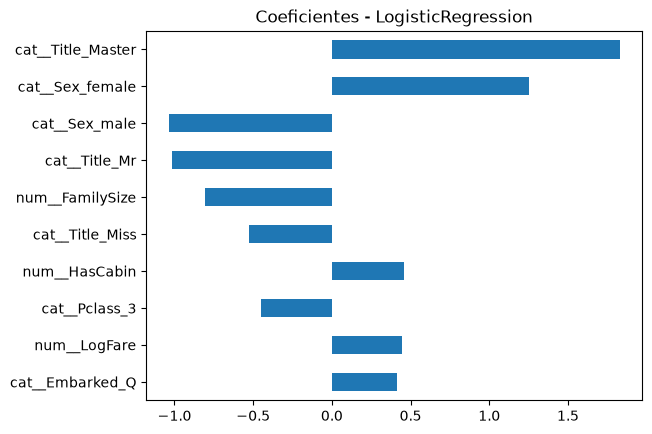

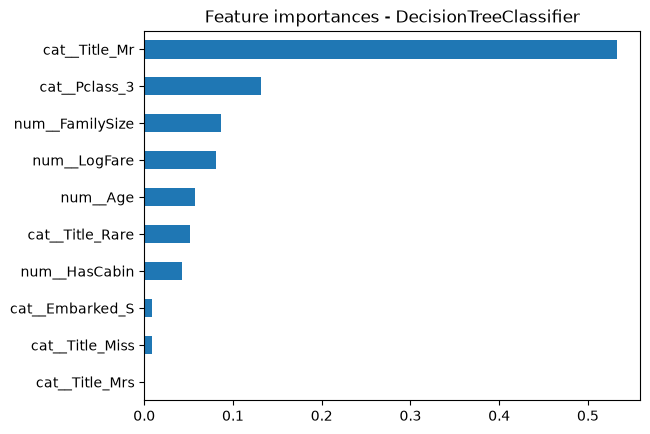

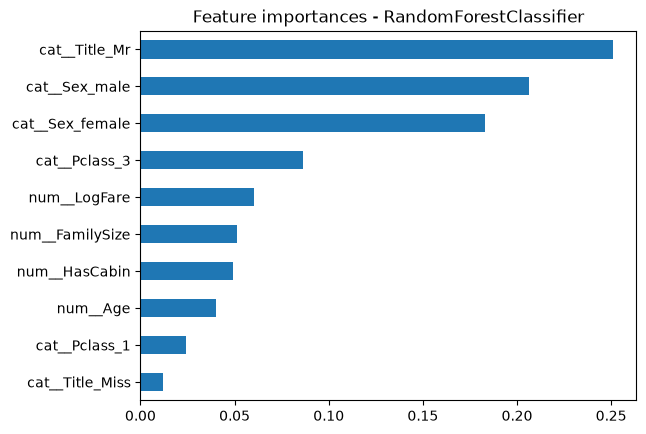

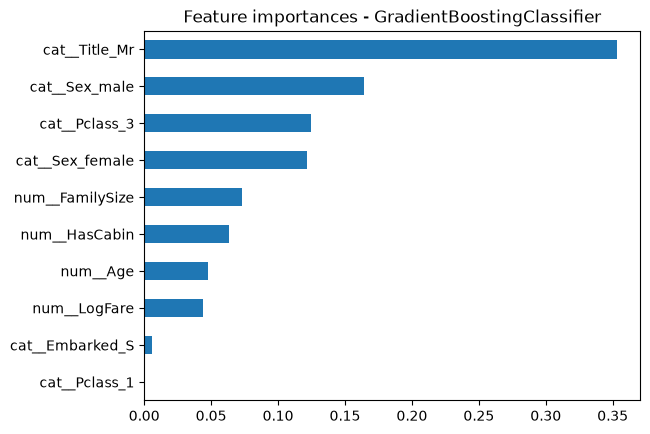

In [9]:
#14 Interpretation 

feature_names = {}

for (name, model) in modelos.items(): 
    mejor_modelo = search_list[name].best_estimator_
    feature_names[name] = (mejor_modelo.named_steps["preprocessor"].get_feature_names_out())          #"preprocessor" serveix per accedir al pas del Pipeline on encara tenim les columnes del principi (OneHotEncoder crea columnes noves xex)          

    if name in ("RandomForestClassifier","DecisionTreeClassifier","GradientBoostingClassifier"):       #árboles (tienen feature_importances)
        importancias = mejor_modelo.named_steps["modelo"].feature_importances_

        imp = pd.Series(importancias, index=feature_names[name]).sort_values(ascending=False).head(10)

        plt.figure()
        imp.plot(kind="barh")
        plt.gca().invert_yaxis()   # para que la más importante quede arriba
        plt.title(f"Feature importances - {name}")

    elif name in ("LogisticRegression", "LinearRegression", "SVC"):
        coefs = mejor_modelo.named_steps["modelo"].coef_[0]

        coef_series = pd.Series(coefs, index=feature_names[name]).sort_values(key=abs, ascending=False).head(10)

        plt.figure()
        coef_series.plot(kind="barh")
        plt.gca().invert_yaxis()
        plt.title(f"Coeficientes - {name}")

    else:
        print(f"{name}: Nothing to see.")
    
plt.show()


In [10]:
#VotingClassifier Per les votacions

from sklearn.ensemble import VotingClassifier

estimadores = [
    (name, search_list[name].best_estimator_)           #search_list[name].best_estimator_ = mejor_modelo
    for name in modelos.keys()
]

voting_soft = VotingClassifier(estimators=estimadores, voting="soft")
voting_hard = VotingClassifier(estimators=estimadores, voting="hard")

for (name, voting_model) in [("Voting Soft", voting_soft),("Voting Hard", voting_hard)]: 
    scores = cross_val_score(voting_model, X_train, y_train, cv=cv, scoring="f1")
    print(f"{name}: F1 = {scores.mean():.4f} +- {scores.std():.4f}")
print()

#Comparación de los modelos por separado

for (name, model) in estimadores:
    scores_indiv = cross_val_score(model, X_train, y_train, cv=cv, scoring="f1")
    print(f"{name}: F1 = {scores_indiv.mean():.4f} +- {scores_indiv.std():.4f}")


Voting Soft: F1 = 0.7711 +- 0.0225
Voting Hard: F1 = 0.7778 +- 0.0314

LogisticRegression: F1 = 0.7707 +- 0.0162
KNeighborsClassifier: F1 = 0.7604 +- 0.0180
DecisionTreeClassifier: F1 = 0.7500 +- 0.0321
RandomForestClassifier: F1 = 0.7760 +- 0.0418
GradientBoostingClassifier: F1 = 0.7798 +- 0.0456


F1 en CV (mejor combinación de hiperparámetros por modelo):
GradientBoostingClassifier    0.7798
RandomForestClassifier        0.7760
LogisticRegression            0.7707
KNeighborsClassifier          0.7604
DecisionTreeClassifier        0.7500
dtype: float64

Modelo elegido: GradientBoostingClassifier

Accuracy hold-out: 0.7933
F1 hold-out:       0.7132

              precision    recall  f1-score   support

           0       0.81      0.87      0.84       110
           1       0.77      0.67      0.71        69

    accuracy                           0.79       179
   macro avg       0.79      0.77      0.78       179
weighted avg       0.79      0.79      0.79       179



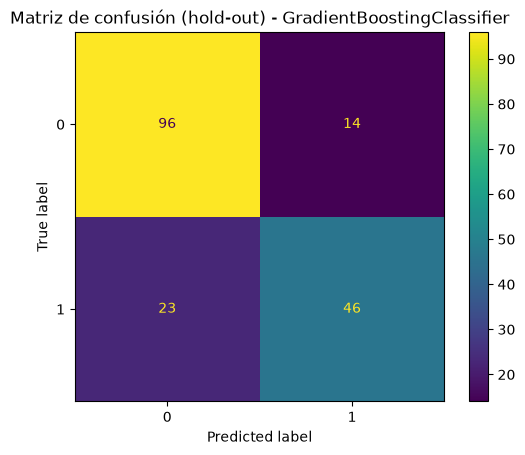

In [11]:
#15 Selección del modelo final y evaluación en hold-out

from sklearn.metrics import accuracy_score, f1_score
from sklearn.metrics import ConfusionMatrixDisplay

cv_summary = pd.Series({name: s.best_score_ for name, s in search_list.items()}).sort_values(ascending=False)           # Elegimos el mejor modelo según la CV del tuning (no según el hold-out)
print("F1 en CV (mejor combinación de hiperparámetros por modelo):")
print(cv_summary.round(4))

best_name = cv_summary.index[0]
best_model = search_list[best_name].best_estimator_   # ya entrenado con X_train
print(f"\nModelo elegido: {best_name}")

# Evaluación única en el hold-out
pred_holdout = best_model.predict(X_test)
print(f"\nAccuracy hold-out: {accuracy_score(y_test, pred_holdout):.4f}")
print(f"F1 hold-out:       {f1_score(y_test, pred_holdout):.4f}\n")
print(classification_report(y_test, pred_holdout))

ConfusionMatrixDisplay.from_predictions(y_test, pred_holdout)
plt.title(f"Matriz de confusión (hold-out) - {best_name}")
plt.show()

In [12]:
#16 Predicción sobre `test.csv` y generación del `submission.csv`

from pathlib import Path
from sklearn.base import clone

final_model = clone(best_model).fit(X, y)

preds = final_model.predict(test_data[FEATURES])

submission = pd.DataFrame({
    "PassengerId": test_data["PassengerId"],
    "Survived": preds.astype(int),
})

Path("submissions").mkdir(exist_ok=True)
submission.to_csv("submissions/submission.csv", index=False)

print(submission.shape)          # debe ser (418, 2)
print(submission["Survived"].value_counts(normalize=True).round(3))
submission.head()

(418, 2)
Survived
0    0.624
1    0.376
Name: proportion, dtype: float64


,PassengerId,Survived
0,892,0
1,893,1
2,894,0
3,895,0
4,896,1
